<a href="https://colab.research.google.com/github/u1460072/IS-4487-Labs/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

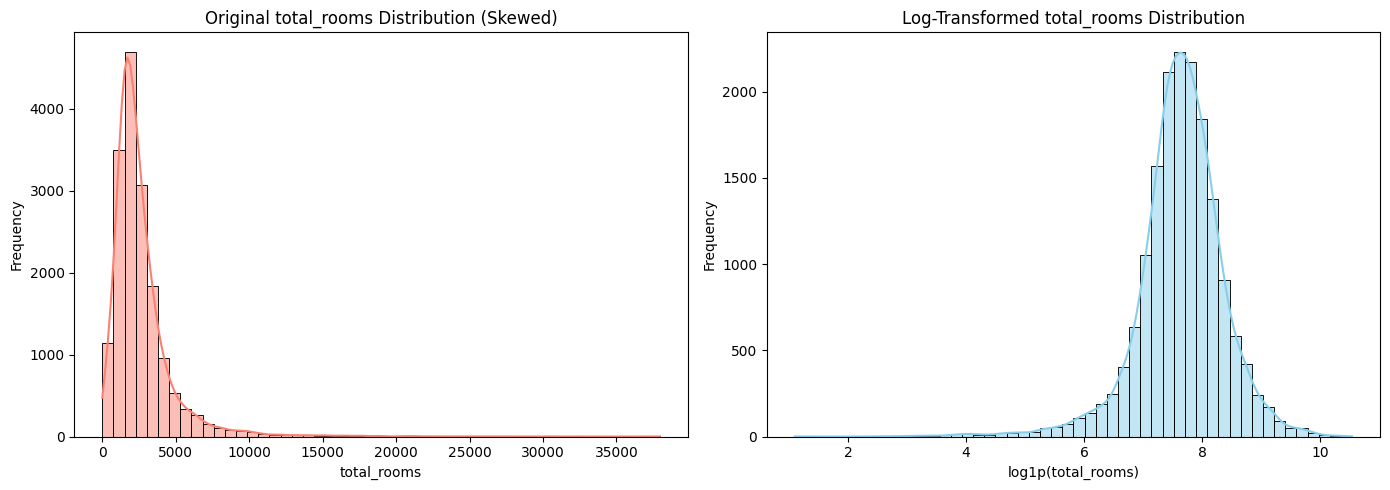

In [3]:
import os

file_path = '/content/listings.csv.gz'
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
else:
    df = pd.read_csv('/content/sample_data/california_housing_train.csv')

column_to_check = 'price' if 'price' in df.columns else 'total_rooms'

if column_to_check == 'price' and df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').astype(float)

data_to_plot = df[column_to_check].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data_to_plot, bins=50, kde=True, ax=axes[0], color='salmon')
axes[0].set_title(f'Original {column_to_check} Distribution (Skewed)')
axes[0].set_xlabel(column_to_check)
axes[0].set_ylabel('Frequency')

transformed_column = np.log1p(data_to_plot)

sns.histplot(transformed_column, bins=50, kde=True, ax=axes[1], color='skyblue')
axes[1].set_title(f'Log-Transformed {column_to_check} Distribution')
axes[1].set_xlabel(f'log1p({column_to_check})')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined price because it was one of the best options as it can have extreme outliers and a large difference between the min and max.

2. I log transformed the price becuase logarithmic scaling can compress the wide range out outliers that are in the price column. It makes it more evenly distributed.

3. The transformed version helped make the data more useable for analysis and stakeholder review as it makes the patterns in the data clearer and makes comparing variables more accurate and meaningful.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [6]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

price_col = 'price' if 'price' in df.columns else 'median_house_value'
nights_col = 'minimum_nights' if 'minimum_nights' in df.columns else 'housing_median_age'

# Min-Max scale (Fixed missing closing parenthesis)
df['Price_MinMax'] = (df[price_col] - df[price_col].min()) / (df[price_col].max() - df[price_col].min())

# Z-score scale
df['Nights_ZScore'] = (df[nights_col] - df[nights_col].mean()) / df[nights_col].std()


### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. The two columns that I scaled were Price and minimum nights. For Price I used the Min-Max scale and for minimum nights I used the Z-score scale.

2. The scaled values might be more useful than the originals when a business needs to compare values and variables in a more fair manner if there are outliers and inconsistencies in the dataset. It also helps provide better interpretability and stability for balanced model inputs. It can help to see if there is a difference in correlation between the scaled and non scaled values to see if it is a issue Airbnb needs to capitalize on or fix.

3. The teams at Airbnb that would benefit from this transformation are customer insight teams to see if price and minimum number of nights gets more clicks or behavior. Operations teams would also find the tranformation helpful to help them be able to process the relationship fairly. Lastly, analyst teams and product managers could find them beneficial for the same reasons.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [9]:
bins = 3
labels = ['Low', 'Medium', 'High']

review_col = 'number_of_reviews' if 'number_of_reviews' in df.columns else 'housing_median_age'

df['Review_Category'] = pd.cut(df[review_col], bins=bins, labels=labels)

### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped number of reviews and housing median age into the three bins of low, medium, and high.

2. Someone would prefer this grouped view over the raw number as it can condense a large amount of numbers into a clean and instinctive business groups.

3. The teams at Airbnb that this would help are the Marketing and Operational teams who are wanting to create tailored campaigns and rewards for hosts that are active or get a higher number of reviews.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [11]:
price_col = 'price' if 'price' in df.columns else 'median_house_value'
nights_col = 'minimum_nights' if 'minimum_nights' in df.columns else 'housing_median_age'

df['Price_Per_night'] = df[price_col] / df[nights_col]

df['Long_term_stay'] = df[nights_col].apply(lambda x: 1 if x > 30 else 0)

### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. The two new columns that I created were price per night and long stay flags. I created price per night as it is a helpful metric to keep track of and analyze the price across different stay lengths, for long stay flags, this can help identify listings that have stays that are longer than 30 days which is helpful for teams who may treat long-term stays differently.

2. The people who would use the new columns are customers, the platform, marketing, managers, and strategy teams for price. For flagged long-term stays, managers, operations, and marketing teams would find this helpful.

3. These could help someone make a better decision as if they knew the price per night, they could specifically market or promote that property with such metrics as compared to other properties on the platform, or it could help a customer that is on a budget book and compare properties to see what would be feasible for them. It also helps the platform find long-term stays to market to customers specifically looking for that.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [15]:
review_encoded = pd.get_dummies(df['Review_Category'], prefix='Review')
df = pd.concat([df, review_encoded], axis=1)

### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded the review category column as it was the only categorical column I found in my dataset after using df.info()
2. The encoding method that I used was one-hot encoding to create the categorical data into binary columns.
3. This transformation could help a pricing model, dashboard, or business report as it can help the pricing models understand how reviews affect demand, it helps dashboards become easier and quicker to interpret, and helps upper management identify patterns between reviews and other columns.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [16]:
df.to_csv('cleaned_airbnb_data_7.csv', index=False)
print("Dataset exported successfully as 'cleaned_airbnb_data_7.csv'!")

Dataset exported successfully as 'cleaned_airbnb_data_7.csv'!


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The transformation step that felt the most important during this assignment was step 6. encode a categorical column

2.

3.
4.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"